# 05 — Held-out WBC localization evaluation

**Purpose:** Evaluate the completed best.pt on the test split only, with official Ultralytics detection metrics.

**Required inputs:** Completed main run from notebook 04 and unchanged processed dataset.

**Saved outputs:** `outputs/paper_results/detection_metrics.csv/.json` and `outputs/figures/test_evaluation/<run>/`.

## 1. Load the central configuration

The root is found from the notebook location or the installed package. Set `LEUKEMIA_YOLO_CONFIG` only for synthetic smoke tests or an alternate config.

In [1]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "config.py").is_file():
        sys.path.insert(0, str(candidate))
        break
from src.config import load_config, ensure_outputs
cfg = load_config()
out = ensure_outputs(cfg)
os.chdir(cfg["root"])
print("Project root:", cfg["root"])
print("Configuration:", cfg["config_path"])

Project root: D:\CellCancer\leukemia-yolo
Configuration: D:\CellCancer\leukemia-yolo\config.local.yaml


## 2. Resolve exact checkpoint and test size

Checkpoint provenance is checked against the frozen dataset fingerprint.

In [2]:
from src.training import resolve_checkpoint
from src.validation import validate_processed
checkpoint = resolve_checkpoint(cfg)
data_check = validate_processed(cfg["processed_data_path"])
print("Checkpoint:", checkpoint)
print("Held-out test images:", data_check["splits"]["test"]["images"])

Checkpoint: D:\CellCancer\leukemia-yolo\outputs\checkpoints\main_20261013T090007Z_a25a7934\weights\best.pt
Held-out test images: 72


## 3. Run test evaluation

The shared evaluator invokes `YOLO(best.pt).val(data=..., split='test', plots=True)` and reads box precision/recall/mAP.

In [3]:
from src.evaluation import evaluate, evaluation_figure_paths
evaluation = evaluate(cfg)
import pandas as pd
display(pd.DataFrame([evaluation["metrics"]]))
print("Evaluation figures:", evaluation["figures"])

Ultralytics 8.4.176  Python-3.11.17 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 207.0±45.6 MB/s, size: 19.6 KB)
val: Scanning D:\CellCancer\leukemia-yolo\data\processed\BCCD_YOLO\labels\test... 72 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 72/72 2.1Kit/s 0.0s
val: New cache created: D:\CellCancer\leukemia-yolo\data\processed\BCCD_YOLO\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.2it/s 4.3s0.3s9s
                   all         72         71      0.945          1      0.965      0.771
Speed: 2.0ms preprocess, 6.6ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to D:\CellCancer\leukemia-yolo\outputs\figures\test_evaluation\test_20261013T090639Z_e95cdc1c


,precision,recall,mAP50,mAP50_95
0,0.945026,1.0,0.964625,0.770725


Evaluation figures: D:\CellCancer\leukemia-yolo\outputs\figures\test_evaluation\test_20261013T090639Z_e95cdc1c


## 4. Show curves and confusion matrix

Framework plots are generated from the held-out split. Missing optional plot files are labeled explicitly.

confusion_matrix.png D:\CellCancer\leukemia-yolo\outputs\figures\test_evaluation\test_20261013T090639Z_e95cdc1c\confusion_matrix.png


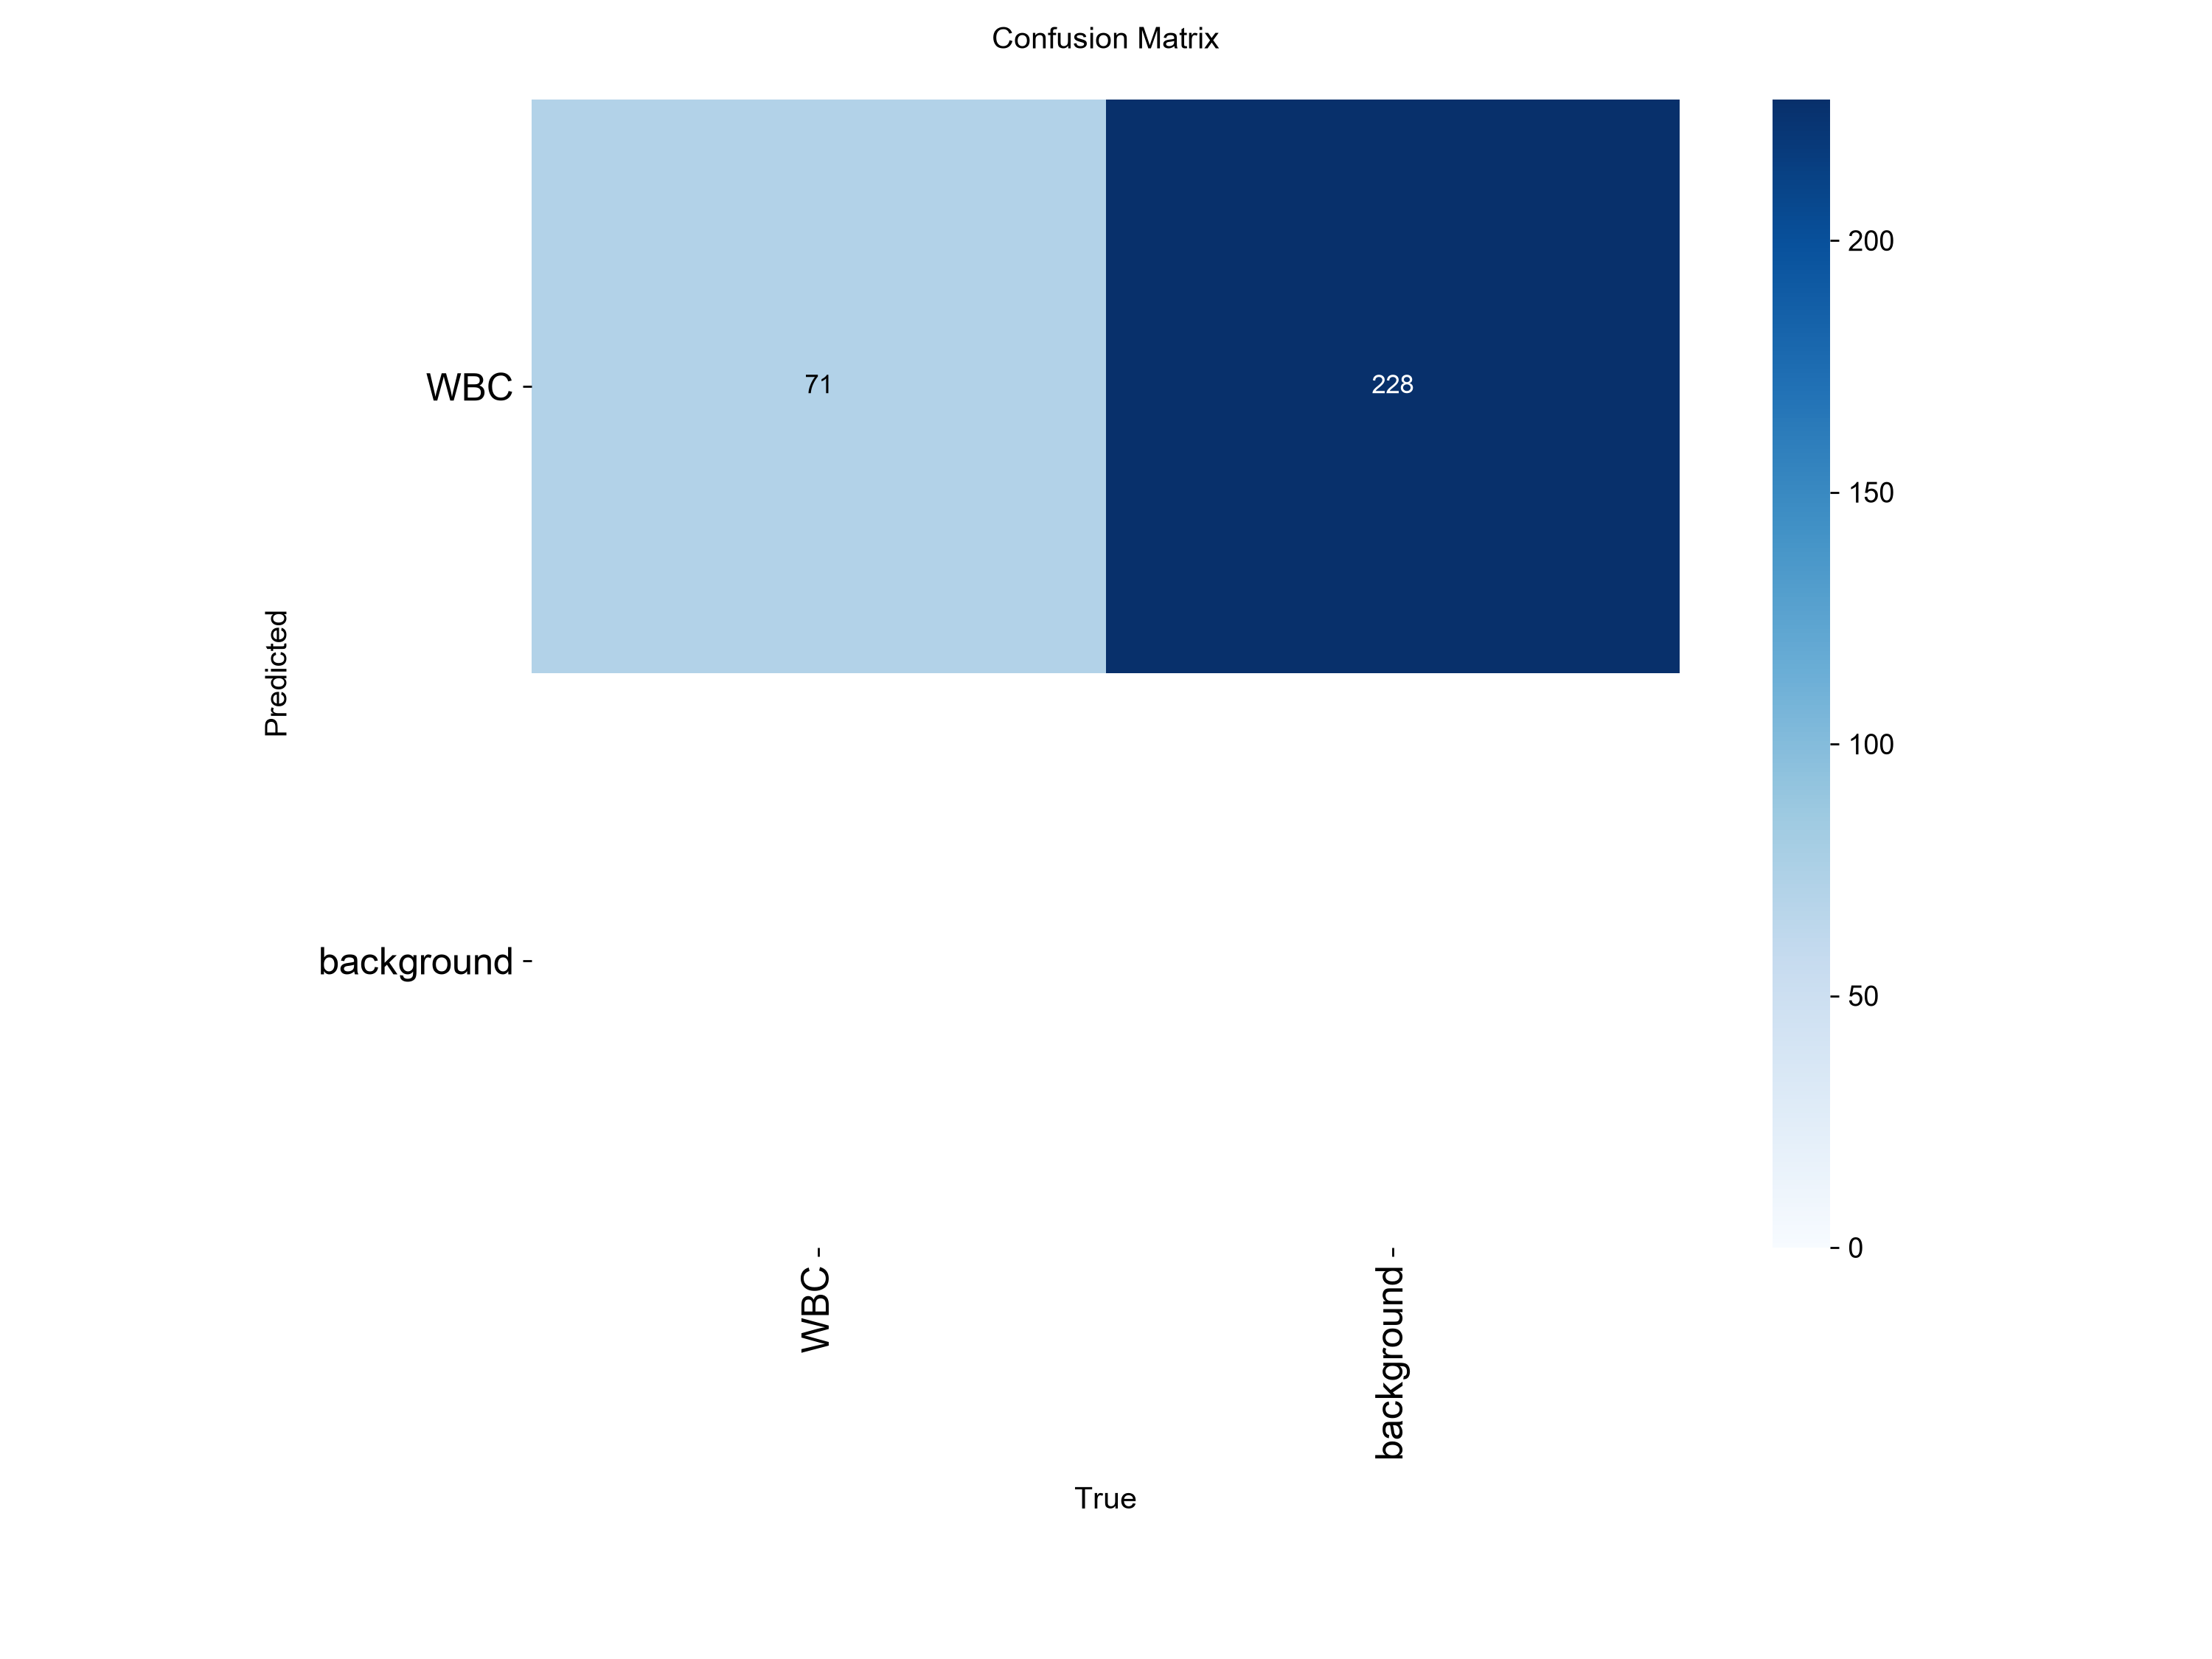

BoxPR_curve.png D:\CellCancer\leukemia-yolo\outputs\figures\test_evaluation\test_20261013T090639Z_e95cdc1c\BoxPR_curve.png


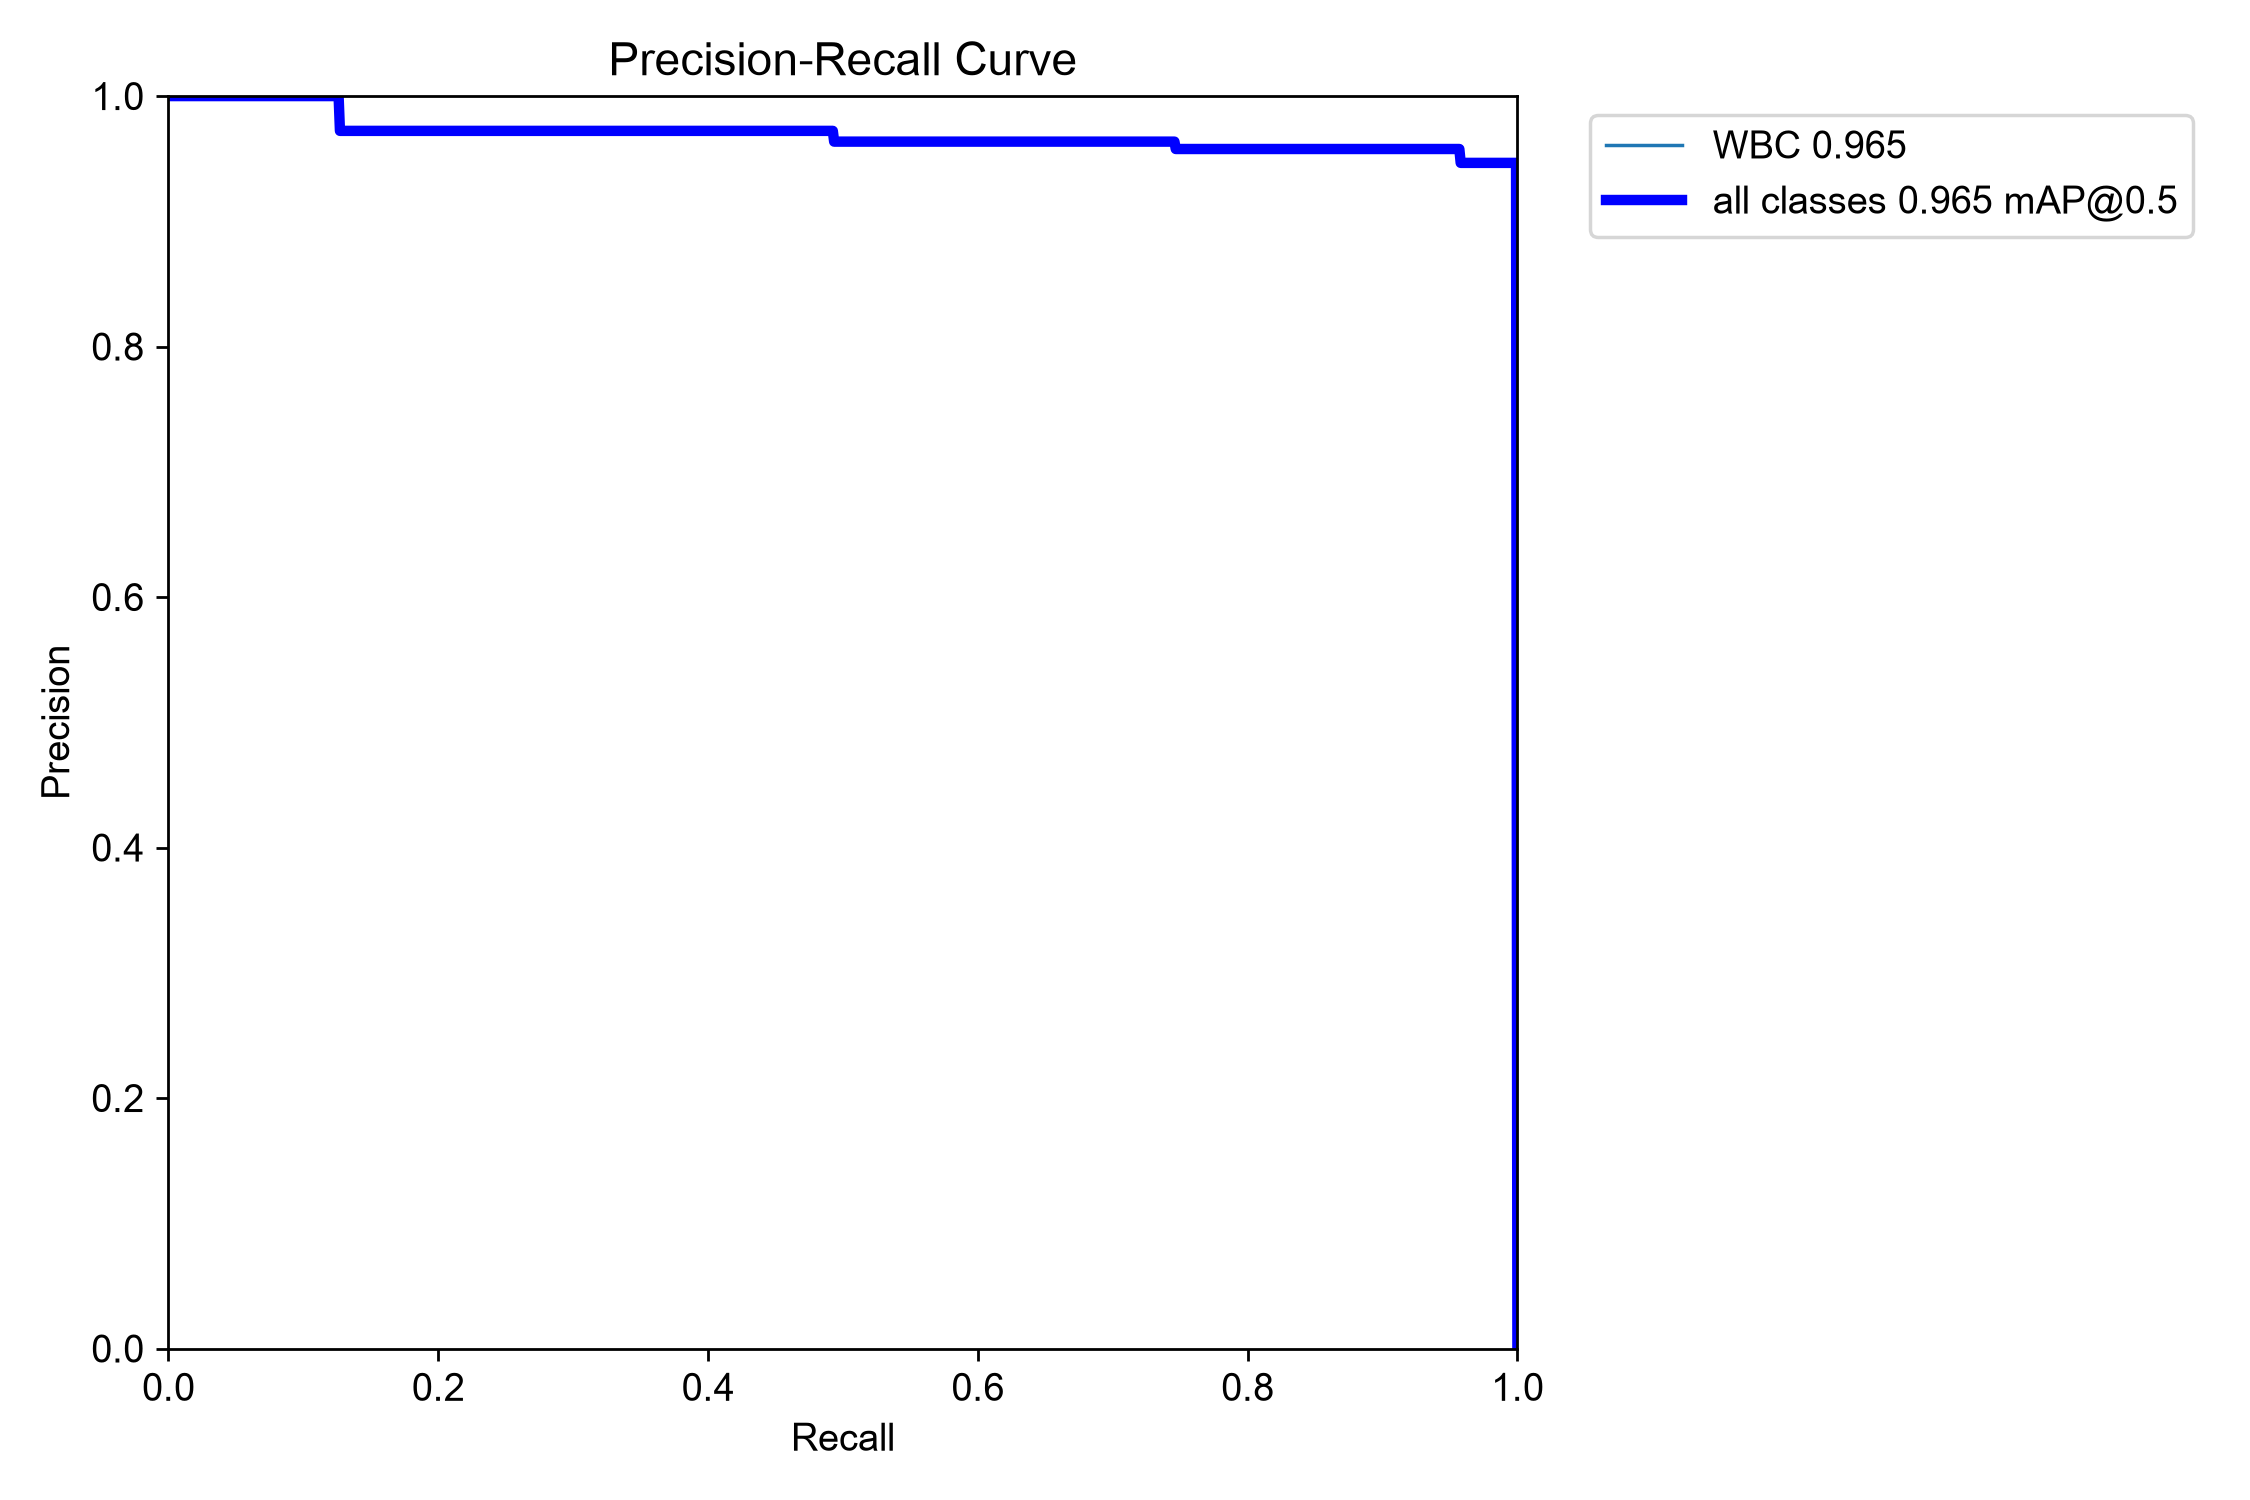

BoxF1_curve.png D:\CellCancer\leukemia-yolo\outputs\figures\test_evaluation\test_20261013T090639Z_e95cdc1c\BoxF1_curve.png


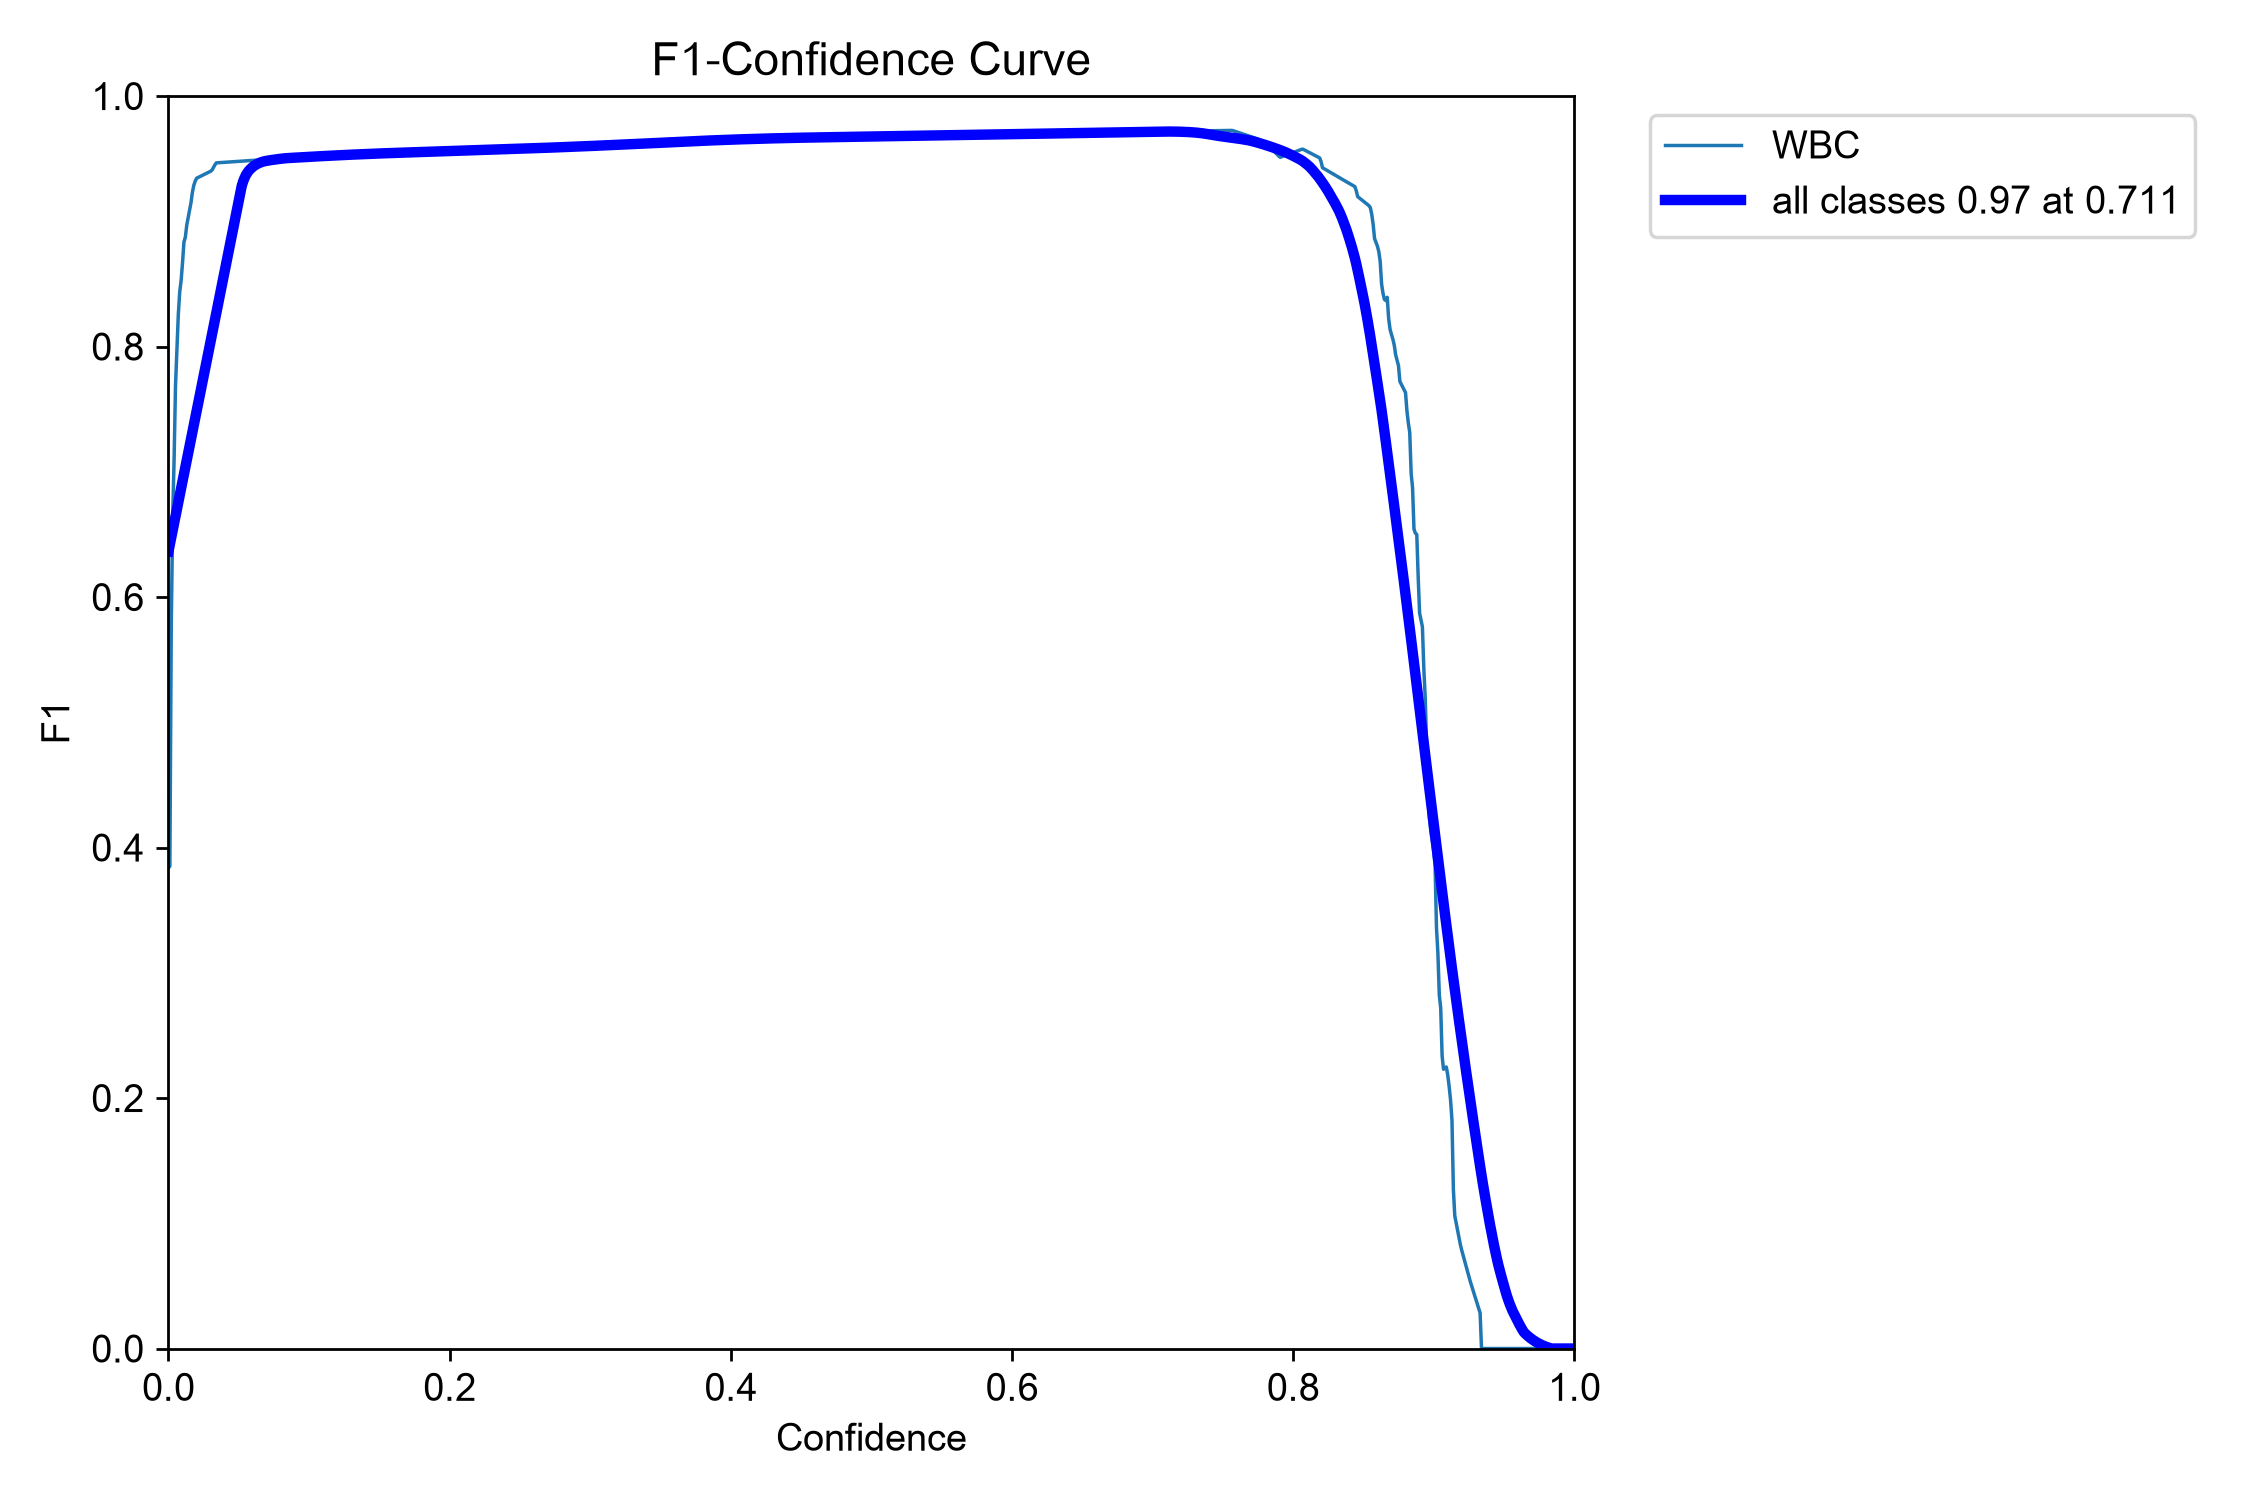

In [4]:
from IPython.display import display, Image as IPImage
for name,path in evaluation_figure_paths(evaluation).items():
    print(name, path if path.is_file() else "Not available")
    if path.is_file(): display(IPImage(filename=str(path)))

## 5. Saved result and interpretation

Metrics measure WBC localization. They do not measure leukemia or blast classification.

In [5]:
assert evaluation["split"] == "test"
assert (out / "paper_results" / "detection_metrics.json").is_file()
print("PASS — test-only WBC localization results saved for this checkpoint. Next: notebook 06.")

PASS — test-only WBC localization results saved for this checkpoint. Next: notebook 06.


## Next notebook

Open **06_WBC_Detection.ipynb**.